# Phase 5b — Text models: does the description help?

**Supervised vs self-supervised.** Our task is **supervised**: each CVE has a label (exploited within 90 days or
not) and every model below is fit to those labels. The sentence encoders (all-MiniLM-L6-v2, bge-small-en-v1.5)
were **pre-trained without our labels**, by self-supervised / contrastive learning on large text corpora, to map
sentences with similar meaning to nearby vectors. Using them here is **transfer learning**: the encoder is
frozen, and only the small model on top learns from our labels.

Text input = `description_day0` (Decision 10: later-added exploitation phrases removed). Dev only; the test set
is not touched. **Selection rule** (all Phase 5 models): mean recall@110 per month over WF 2023, WF 2024-H1 and val.

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "mpl")); os.environ.setdefault("LOKY_MAX_CPU_COUNT", "8")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from metrics import recall_at_k, recall_curve, random_recall_at_k, bootstrap_recall_at_k, ci_table, pr_auc
from description_leak import PHRASES, phrase_flags
from features import load_kev_raw
from tabular_models import build_X, make_hgb, views
import text_models as txm

FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
BLUE, ORANGE, AQUA, VIOLET, MAGENTA, GREEN, INK, INK2, GRID, SURF = ("#2a78d6", "#eb6834", "#1baf7a", "#6250d6",
    "#e87ba4", "#008300", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb")
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 11, "font.size": 9.5})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
def save(fig, name): fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
K_MAIN, K_GEN = 110, 305
HGB_BEST = dict(encoding="onehot", learning_rate=0.03, max_leaf_nodes=15, min_samples_leaf=100)   # 05a selection

dev = pd.read_parquet(ROOT / "data" / "dev.parquet")
y = dev["label"].to_numpy()
kev = load_kev_raw(sorted((ROOT / "data" / "raw").glob("kev_*.csv"))[-1])
X_tab = build_X(dev, kev)
EMB = {n: txm.load_embeddings(n, dev) for n in ["minilm", "bge_small"]}
for n in EMB:
    m = json.loads((ROOT / "data" / "embeddings" / f"{n}_meta.json").read_text())
    print(f"{n:10s} {m['model']} @ {m['revision'][:12]}  dim={m['dim']}  n={m['n']:,}  ({m['device']}, {m['seconds']}s)")

def row(name, r):
    return {"model": name, "val@110": r["val@110"], "val@305": r["val@305"], "wf_2023@110": r["wf_2023@110"],
            "wf_2024h1@110": r["wf_2024h1@110"], "worst": r["worst"], "selection": r["selection"]}
RESULTS = {}     # name -> eval_periods output, for the final table

minilm     sentence-transformers/all-MiniLM-L6-v2 @ 1110a243fdf4  dim=384  n=93,842  (mps, 145.9s)
bge_small  BAAI/bge-small-en-v1.5 @ 5c38ec7c405e  dim=384  n=93,842  (mps, 267.0s)


## 1. Reference points on the same three periods
The best day-0 rule and the 05a gradient boosting model, re-scored here so every number below is comparable.

In [2]:
rule = 100 * phrase_flags(dev["description_day0"], PHRASES).any(axis=1).to_numpy() + dev["cvss_cna_score"].fillna(-1).to_numpy()
RESULTS["phrase, then CVSS (CNA)"] = txm.eval_periods(dev, lambda f, e: rule[e])
RESULTS["gradient boosting (05a)"] = txm.eval_periods(dev, lambda f, e: make_hgb(**HGB_BEST).fit(X_tab[f], y[f]).predict_proba(X_tab[e])[:, 1])
ref = pd.DataFrame([row(k, v) for k, v in RESULTS.items()]).set_index("model")
display((100 * ref).round(1))

,val@110,val@305,wf_2023@110,wf_2024h1@110,worst,selection
model,,,,,,
"phrase, then CVSS (CNA)",28.1,42.7,39.3,34.9,28.1,34.1
gradient boosting (05a),47.1,67.6,39.7,55.6,39.7,47.4


## 2. Text only: logistic regression on frozen embeddings
Which encoder, and how much regularisation? Grid: encoder × C, class_weight = balanced.

In [3]:
rows = []
for emb in EMB:
    for C in [0.1, 1.0, 10.0]:
        r = txm.eval_periods(dev, txm.text_lr_scorer(EMB[emb], y, C))
        rows.append({"encoder": emb, "C": C, **{k: v for k, v in r.items() if not k.startswith("_")}})
tlr = pd.DataFrame(rows).sort_values("selection", ascending=False).reset_index(drop=True)
display(tlr.round(3)); tlr.to_csv(TAB / "05b_text_lr_grid.csv", index=False)
BEST_EMB, BEST_C = tlr.loc[0, "encoder"], float(tlr.loc[0, "C"])
E = EMB[BEST_EMB]
RESULTS["text LR"] = txm.eval_periods(dev, txm.text_lr_scorer(E, y, BEST_C))
print(f"selected: encoder = {BEST_EMB}, C = {BEST_C}")

,encoder,C,val@110,val@305,wf_2023@110,wf_2024h1@110,worst,selection
0,minilm,1.0,0.235,0.456,0.430,0.511,0.235,0.392
1,minilm,0.1,0.250,0.485,0.455,0.467,0.250,0.390
2,bge_small,1.0,0.382,0.647,0.364,0.400,0.364,0.382
3,bge_small,10.0,0.353,0.559,0.347,0.400,0.347,0.367
4,minilm,10.0,0.235,0.485,0.380,0.444,0.235,0.353
5,bge_small,0.1,0.338,0.632,0.322,0.356,0.322,0.339


selected: encoder = minilm, C = 1.0


**Takeaway**: Text alone carries real signal. The best text-only logistic regression (MiniLM, C = 1) has a three-period selection score of **39.2%**, above the best rule's 34.1%. It is strong on the walk-forward periods (**43.0% / 51.1%**) but weak on val (**23.5%**, below the rule's 28.1%), so it is unstable. Surprisingly the 'stronger' encoder (bge-small) is better on val (38.2%) but worse on the two walk-forward periods, and loses on the selection rule (38.2% vs 39.2%). With 45–121 positives per period these encoder differences are within noise.

## 3. Text only: a small neural network (PyTorch)
An MLP on the embedding: Linear → ReLU → Dropout(0.2) blocks, class-weighted BCE (positive weight =
negatives/positives), AdamW. **The last 6 months of each training period are the early-stopping set**
(patience 6, max 60 epochs; val is never used). The net is first trained on the earlier months only, to find the
best number of epochs; it is then **refit on the full training period (stopping months included) for that many
epochs**, same seed, so it sees the same data as gradient boosting. Grid: 3 architectures × 2 learning rates
(refit version, seed 0); the selected setting is re-run with **5 seeds**, in both versions (stop-set only vs
refit) to show what the refit is worth.

,hidden,lr,val@110,val@305,wf_2023@110,wf_2024h1@110,worst,selection
0,"(64,)",0.001,0.309,0.500,0.421,0.467,0.309,0.399
1,"(256, 64)",0.001,0.309,0.515,0.438,0.444,0.309,0.397
2,"(64,)",0.000,0.294,0.485,0.421,0.467,0.294,0.394
3,"(256,)",0.001,0.309,0.485,0.421,0.444,0.309,0.392
4,"(256,)",0.000,0.265,0.500,0.421,0.444,0.265,0.377
5,"(256, 64)",0.000,0.294,0.500,0.430,0.400,0.294,0.375


selected MLP: hidden = (64,), lr = 0.001


,seed,"best_epochs (WF23, WF24H1, val)",val@110,val@305,wf_2023@110,wf_2024h1@110,worst,selection
0,0,"[5, 13, 6]",0.309,0.500,0.421,0.467,0.309,0.399
1,1,"[7, 15, 5]",0.294,0.500,0.430,0.444,0.294,0.389
2,2,"[7, 17, 4]",0.294,0.500,0.421,0.444,0.294,0.387
3,3,"[7, 13, 4]",0.309,0.500,0.438,0.467,0.309,0.405
4,4,"[7, 13, 6]",0.324,0.515,0.438,0.422,0.324,0.395


text MLP (64,), lr=0.001: stop-set only vs refit, 5 seeds


,stop-set only,refit on full period
mean wf_2023@110,28.3,43.0
mean wf_2024h1@110,44.0,44.9
mean val@110,29.4,30.6
mean val@305,49.7,50.3
mean selection,33.9,39.5
worst seed (selection),32.4,38.7


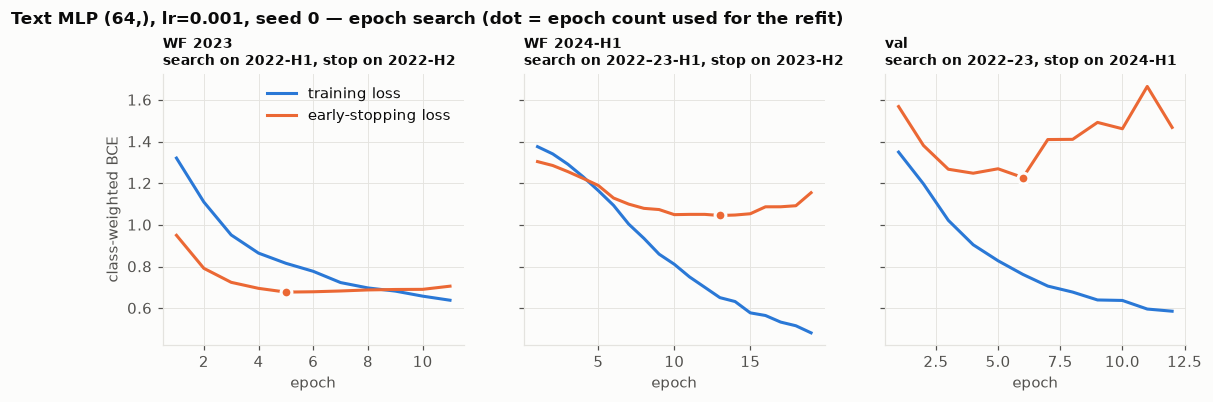

In [4]:
ARCHS, LRS = [(64,), (256,), (256, 64)], [1e-3, 3e-4]
rows = []
for h in ARCHS:
    for lr in LRS:
        r = txm.eval_periods(dev, txm.mlp_scorer(dev, E, y, h, lr, seed=0))
        rows.append({"hidden": str(h), "lr": lr, **{k: v for k, v in r.items() if not k.startswith("_")}})
nng = pd.DataFrame(rows).sort_values("selection", ascending=False).reset_index(drop=True)
display(nng.round(3)); nng.to_csv(TAB / "05b_text_mlp_grid.csv", index=False)
NN_H, NN_LR = eval(nng.loc[0, "hidden"]), float(nng.loc[0, "lr"])
print(f"selected MLP: hidden = {NN_H}, lr = {NN_LR}")

def run_seeds(make_scorer, n=5):
    rows_, scores_, curves_, epochs_ = [], [], None, []
    for seed in range(n):
        cv, ep = ([] if seed == 0 else None), []
        r = txm.eval_periods(dev, make_scorer(seed, cv, ep))
        if seed == 0: curves_ = cv
        rows_.append({"seed": seed, "best_epochs (WF23, WF24H1, val)": str(ep), **{k: v for k, v in r.items() if not k.startswith("_")}})
        scores_.append(r["_scores"])
    return pd.DataFrame(rows_), scores_, curves_

both = {}
for refit in (False, True):
    both[refit] = run_seeds(lambda seed, cv, ep, rf=refit: txm.mlp_scorer(dev, E, y, NN_H, NN_LR, seed, curves=cv, refit=rf, epochs_log=ep))
seeds, seed_scores, curves = both[True]
display(seeds.round(3))
cmp_ = pd.DataFrame({("stop-set only" if not rf else "refit on full period"):
        {**{f"mean {k}": both[rf][0][k].mean() for k in ["wf_2023@110", "wf_2024h1@110", "val@110", "val@305", "selection"]},
         "worst seed (selection)": both[rf][0]["selection"].min()} for rf in (False, True)})
print(f"text MLP {NN_H}, lr={NN_LR}: stop-set only vs refit, 5 seeds"); display((100 * cmp_).round(1))
cmp_.to_csv(TAB / "05b_text_mlp_refit_vs_stopset.csv")
# seed-averaged ensemble of the 5 nets, used later for fusion
avg_scores = {p: np.mean([s[p] for s in seed_scores], axis=0) for p in seed_scores[0]}
RESULTS["text MLP (5 seeds)"] = {**seeds.drop(columns="seed").mean(numeric_only=True).to_dict(), "_scores": avg_scores, "_seed_table": seeds}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, (pname, h) in zip(axes, zip(["WF 2023\nsearch on 2022-H1, stop on 2022-H2", "WF 2024-H1\nsearch on 2022–23-H1, stop on 2023-H2",
                                    "val\nsearch on 2022–23, stop on 2024-H1"], curves)):
    ax.plot(h["epoch"], h["train_loss"], color=BLUE, lw=2, label="training loss")
    ax.plot(h["epoch"], h["es_loss"], color=ORANGE, lw=2, label="early-stopping loss")
    best = h.loc[h["es_loss"].idxmin()]
    ax.scatter(best["epoch"], best["es_loss"], color=ORANGE, s=50, zorder=5, edgecolor=SURF, linewidth=2)
    ax.set_title(pname, loc="left", fontsize=9); ax.set_xlabel("epoch")
axes[0].set_ylabel("class-weighted BCE"); axes[0].legend(frameon=False)
fig.suptitle(f"Text MLP {NN_H}, lr={NN_LR}, seed 0 — epoch search (dot = epoch count used for the refit)", x=0.01, y=1.06, ha="left", fontweight="bold")
save(fig, "05b_01_mlp_loss_curves")

**Takeaway**: The small MLP (one hidden layer of 64, lr = 1e-3) is chosen; all six settings fall within 37.5–39.9%. Over 5 seeds its selection score is **39.5% on average, worst seed 38.7%**, barely above the text LR (39.2%). **The refit matters:** training only on the months before the stopping set gives a selection score of **33.9%**, refitting on the full period for the same epoch count gives **39.5%** (+5.6 points). Almost all of the gain is in WF 2023 (**28.3% → 43.0%**), where the stop-set-only net had only 6 months (2022-H1) to learn from. The loss curves show the usual pattern: training loss keeps falling while the stopping-set loss bottoms out after 5–13 epochs.

## 4. Combining tabular and text
* **(a) One network on both** — tabular features (one-hot + scaled, fitted inside each period) concatenated with
  the embedding; same MLP recipe, small grid, 5 seeds.
* **(b) Gradient boosting + text score** — the 05a boosting model with one extra feature: the text-LR score.
  For training rows the score is **out-of-fold** (5 folds grouped by vendor|month, so no row's text score was fit
  on its own label or its twins'); evaluation rows get a text model fit on the whole training period.
* **(c) Late fusion** — average of the two models' within-month percentile ranks (gradient boosting and the best
  text-only model). No extra fitting.

In [5]:
rows = []
for h in [(64,), (256, 64)]:
    for lr in LRS:
        r = txm.eval_periods(dev, txm.tab_text_scorer(dev, X_tab, E, y, h, lr, seed=0))
        rows.append({"hidden": str(h), "lr": lr, **{k: v for k, v in r.items() if not k.startswith("_")}})
cg = pd.DataFrame(rows).sort_values("selection", ascending=False).reset_index(drop=True)
display(cg.round(3)); cg.to_csv(TAB / "05b_tabtext_mlp_grid.csv", index=False)
CH, CLR = eval(cg.loc[0, "hidden"]), float(cg.loc[0, "lr"])
srows, sscores = [], []
for seed in range(5):
    r = txm.eval_periods(dev, txm.tab_text_scorer(dev, X_tab, E, y, CH, CLR, seed))
    srows.append({"seed": seed, **{k: v for k, v in r.items() if not k.startswith("_")}}); sscores.append(r["_scores"])
cseeds = pd.DataFrame(srows)
cs_stop, _, _ = run_seeds(lambda seed, cv, ep: txm.tab_text_scorer(dev, X_tab, E, y, CH, CLR, seed, refit=False, epochs_log=ep))
cmp_a = pd.DataFrame({name: {**{f"mean {k}": t[k].mean() for k in ["wf_2023@110", "wf_2024h1@110", "val@110", "val@305", "selection"]},
                             "worst seed (selection)": t["selection"].min()} for name, t in [("stop-set only", cs_stop), ("refit on full period", cseeds)]})
print(f"(a) tabular+text MLP {CH}, lr={CLR}: stop-set only vs refit, 5 seeds"); display((100 * cmp_a).round(1))
cmp_a.to_csv(TAB / "05b_tabtext_mlp_refit_vs_stopset.csv")
RESULTS["(a) tabular+text MLP (5 seeds)"] = {**cseeds.drop(columns="seed").mean(numeric_only=True).to_dict(),
    "_scores": {p: np.mean([s[p] for s in sscores], axis=0) for p in sscores[0]}, "_seed_table": cseeds}

RESULTS["(b) gradient boosting + OOF text score"] = txm.eval_periods(dev, txm.hgb_text_scorer(dev, X_tab, E, y, BEST_C, HGB_BEST))

text_name = max(["text LR", "text MLP (5 seeds)"], key=lambda n: RESULTS[n]["selection"])
fused = {}
for pname, (_, ev) in views(dev).items():
    part = dev[ev]
    fused[pname] = (txm.month_pct_rank(part, RESULTS["gradient boosting (05a)"]["_scores"][pname])
                    + txm.month_pct_rank(part, RESULTS[text_name]["_scores"][pname])) / 2
RESULTS["(c) late fusion: gradient boosting + " + text_name] = txm.eval_periods(dev, lambda f, e: fused[[k for k, (_, ev) in views(dev).items() if (ev == e).all()][0]])
comb = pd.DataFrame([row(k, v) for k, v in RESULTS.items()]).set_index("model")
display((100 * comb).round(1))

,hidden,lr,val@110,val@305,wf_2023@110,wf_2024h1@110,worst,selection
0,"(256, 64)",0.001,0.397,0.750,0.479,0.422,0.397,0.433
1,"(256, 64)",0.000,0.382,0.750,0.479,0.422,0.382,0.428
2,"(64,)",0.001,0.397,0.721,0.463,0.422,0.397,0.427
3,"(64,)",0.000,0.426,0.721,0.463,0.356,0.356,0.415


(a) tabular+text MLP (256, 64), lr=0.001: stop-set only vs refit, 5 seeds


,stop-set only,refit on full period
mean wf_2023@110,38.7,47.4
mean wf_2024h1@110,39.6,48.0
mean val@110,33.5,38.8
mean val@305,55.6,70.3
mean selection,37.3,44.8
worst seed (selection),34.2,42.6


,val@110,val@305,wf_2023@110,wf_2024h1@110,worst,selection
model,,,,,,
"phrase, then CVSS (CNA)",28.1,42.7,39.3,34.9,28.1,34.1
gradient boosting (05a),47.1,67.6,39.7,55.6,39.7,47.4
text LR,23.5,45.6,43.0,51.1,23.5,39.2
text MLP (5 seeds),30.6,50.3,43.0,44.9,30.6,39.5
(a) tabular+text MLP (5 seeds),38.8,70.3,47.4,48.0,38.8,44.8
(b) gradient boosting + OOF text score,42.6,63.2,42.1,51.1,42.1,45.3
(c) late fusion: gradient boosting + text MLP (5 seeds),42.6,64.7,46.3,51.1,42.6,46.7


**Takeaway**: Adding text to the tabular model does **not** beat gradient boosting alone on the selection rule. (a) The tabular+text network: **44.8%** (5-seed mean, worst seed 42.6%), and the refit again helps a lot (37.3% → 44.8%). (b) Gradient boosting + out-of-fold text score: **45.3%**. (c) Late fusion of gradient boosting and the text MLP: **46.7%**. All are close to gradient boosting alone (**47.4%**). The combinations change *where* the model is good: late fusion has the best worst period (**42.6%** vs 39.7%) and WF 2023 (46.3% vs 39.7%), but it gives up val (42.6% vs 47.1%).

## 5. Validation with bootstrap CIs
Paired bootstrap (2,000 within-month resamples) on val for the main candidates, vs the best rule and vs
gradient boosting (05a). For the neural nets the val scores here are the **average of the 5 seeds' scores**
(a 5-seed ensemble), so their point estimate can differ slightly from the *mean of the 5 seeds' recalls*
shown in sections 3–4.

In [6]:
val_mask = dev["split"].eq("val").to_numpy()
val = dev[val_mask].reset_index(drop=True)
cands = ["phrase, then CVSS (CNA)", "gradient boosting (05a)", "text LR", "text MLP (5 seeds)",
         "(a) tabular+text MLP (5 seeds)", "(b) gradient boosting + OOF text score", [k for k in RESULTS if k.startswith("(c)")][0]]
SC = {c: pd.Series(RESULTS[c]["_scores"]["val"]) for c in cands}
point = {(m, k): recall_at_k(val, s, k) for m, s in SC.items() for k in (K_MAIN, K_GEN)}
boot = bootstrap_recall_at_k(val, SC, [K_MAIN, K_GEN], n_boot=2000, seed=0)
ci = ci_table(boot, point)
tbl = ci.mul(100).round(1).reset_index().pivot(index="method", columns="k"); tbl.columns = [f"{a}@{b}" for a, b in tbl.columns]
display(tbl[[f"{c}@{k}" for k in (K_MAIN, K_GEN) for c in ("point", "lo", "hi")]].sort_values(f"point@{K_MAIN}", ascending=False))
piv = boot.pivot_table(index=["rep", "k"], columns="method", values="recall")
for c in cands[2:]:
    for base in ["phrase, then CVSS (CNA)", "gradient boosting (05a)"]:
        d = 100 * (piv[c] - piv[base]).xs(K_MAIN, level="k")
        print(f"{c} minus {base} @110: {d.mean():+.1f} [{d.quantile(.025):+.1f}, {d.quantile(.975):+.1f}], P(better) = {(d > 0).mean():.0%}")
ci.to_csv(TAB / "05b_val_ci.csv")

,point@110,lo@110,hi@110,point@305,lo@305,hi@305
method,,,,,,
gradient boosting (05a),47.1,35.5,59.7,67.6,56.5,78.7
(b) gradient boosting + OOF text score,42.6,31.6,54.8,63.2,50.7,73.6
(c) late fusion: gradient boosting + text MLP (5 seeds),42.6,30.2,54.5,64.7,54.3,76.9
(a) tabular+text MLP (5 seeds),38.2,26.9,50.0,75.0,63.0,84.2
text MLP (5 seeds),32.4,20.3,42.9,50.0,38.2,63.0
"phrase, then CVSS (CNA)",28.1,16.9,38.2,42.7,31.2,54.5
text LR,23.5,14.3,34.4,45.6,32.9,57.6


text LR minus phrase, then CVSS (CNA) @110: -3.6 [-19.5, +12.3], P(better) = 27%
text LR minus gradient boosting (05a) @110: -23.6 [-37.9, -8.8], P(better) = 0%
text MLP (5 seeds) minus phrase, then CVSS (CNA) @110: +3.7 [-12.7, +21.5], P(better) = 64%
text MLP (5 seeds) minus gradient boosting (05a) @110: -16.2 [-31.9, +0.0], P(better) = 2%
(a) tabular+text MLP (5 seeds) minus phrase, then CVSS (CNA) @110: +11.1 [-2.6, +25.7], P(better) = 92%
(a) tabular+text MLP (5 seeds) minus gradient boosting (05a) @110: -8.9 [-22.4, +4.9], P(better) = 9%
(b) gradient boosting + OOF text score minus phrase, then CVSS (CNA) @110: +15.5 [+2.6, +29.2], P(better) = 99%
(b) gradient boosting + OOF text score minus gradient boosting (05a) @110: -4.4 [-15.4, +7.1], P(better) = 18%
(c) late fusion: gradient boosting + text MLP (5 seeds) minus phrase, then CVSS (CNA) @110: +14.8 [+0.0, +30.3], P(better) = 97%
(c) late fusion: gradient boosting + text MLP (5 seeds) minus gradient boosting (05a) @110: -5.1 [

**Takeaway**: On val at K = 110 no text-based model beats gradient boosting alone: the best are (b) and (c) at **42.6%**, −4.4 and −5.1 points vs gradient boosting (P(better) 18–19%). Both still clearly beat the best rule (**+15.5 points [+2.6, +29.2], P = 99%** for (b); +14.8, P = 97% for (c)). Text-only models are not reliably better than the rule at K = 110 (text MLP +3.7, P = 64%; text LR −3.6, P = 27%). At **K = 305** the picture flips: the tabular+text network catches **75.0%** [63–84], the highest of all models, vs 67.6% for gradient boosting.

## 6. Recall vs capacity (validation)

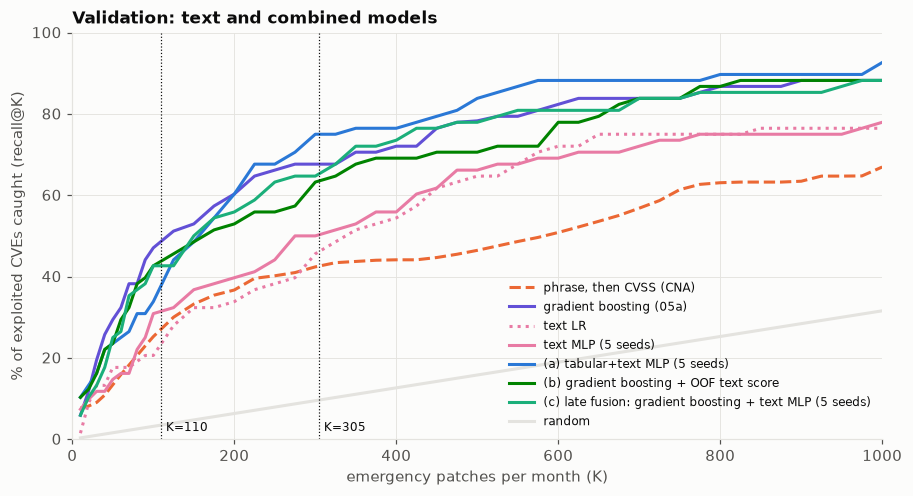

In [7]:
ks = np.unique(np.r_[np.arange(10, 100, 10), np.arange(100, 1001, 25)])
style = {"phrase, then CVSS (CNA)": (ORANGE, "--"), "gradient boosting (05a)": (VIOLET, "-"), "text LR": (MAGENTA, ":"),
         "text MLP (5 seeds)": (MAGENTA, "-"), "(a) tabular+text MLP (5 seeds)": (BLUE, "-"),
         "(b) gradient boosting + OOF text score": (GREEN, "-"), cands[-1]: (AQUA, "-")}
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for m in cands:
    c, ls = style[m]; ax.plot(ks, 100 * recall_curve(val, SC[m], ks), color=c, ls=ls, lw=2, label=m)
ax.plot(ks, [100 * random_recall_at_k(val, k) for k in ks], color=GRID, lw=2, label="random")
for k in (K_MAIN, K_GEN):
    ax.axvline(k, color=INK, lw=0.8, ls=":"); ax.annotate(f"K={k}", (k, 2), fontsize=8, xytext=(3, 0), textcoords="offset points")
ax.set_xlabel("emergency patches per month (K)"); ax.set_ylabel("% of exploited CVEs caught (recall@K)")
ax.set_ylim(0, 100); ax.set_xlim(0, 1000); ax.legend(frameon=False, loc="lower right", fontsize=8)
ax.set_title("Validation: text and combined models", loc="left")
save(fig, "05b_02_val_recall_vs_k")

**Takeaway**: Gradient boosting leads at small capacity (≤ 150/month). Above ~200/month the tabular+text network pulls ahead and stays on top up to 600/month (≈ 88% recall at 575). The text-only curves sit between the rules and the tabular models. So the description adds information that matters **after** the most obvious candidates (known-exploited vendors, critical network bugs) are already patched.

## 7. Planned check: do later description edits move the text model?
Descriptions of exploited CVEs are edited more often after publication (30% vs 12%, Decision 10e). On the
919-CVE history sample (all 319 train+val positives + 600 random negatives) we embed the **reconstructed earliest
description** with the same encoder (same commit, CPU) and re-score. If scores and val recall barely move, the
edits do not matter.

In [8]:
from nvd_history import analyze
from sentence_transformers import SentenceTransformer
meta = json.loads((ROOT / "data" / "embeddings" / f"{BEST_EMB}_meta.json").read_text())
os.environ["HF_HOME"] = str(ROOT / ".cache" / "hf"); os.environ["SENTENCE_TRANSFORMERS_HOME"] = str(ROOT / ".cache" / "hf")
if (ROOT / ".cache" / "hf" / "hub").exists():
    os.environ["HF_HUB_OFFLINE"] = "1"                 # local run: use the cached model, no network
enc = SentenceTransformer(meta["model"], revision=meta["revision"], device="cpu"); enc.max_seq_length = meta["max_seq_length"]
a = analyze().set_index("cve_id")
pos_in_dev = pd.Series(np.arange(len(dev)), index=dev["cve_id"])
rows_s = pos_in_dev[a.index].to_numpy()
E_orig = E.copy()
E_orig[rows_s] = enc.encode(a["original_description"].fillna("").tolist(), batch_size=64, normalize_embeddings=True)
check_today = enc.encode(dev["description_day0"].iloc[rows_s[:50]].tolist(), normalize_embeddings=True)
print(f"re-encoding check (today's text, CPU vs stored MPS embedding): mean cosine {np.mean(np.sum(check_today * E[rows_s[:50]], 1)):.4f}")
print(f"sample CVEs whose description changed: {(a['desc_changed']).sum()} of {len(a)}")
from scipy.stats import spearmanr
tr_mask = dev["split"].eq("train").to_numpy()
out = []
for name, mk in [("text LR", lambda Em: txm.make_text_lr(BEST_C).fit(Em[tr_mask], y[tr_mask]).predict_proba(Em)[:, 1])]:
    s_today, s_orig = mk(E), mk(E_orig)      # same training data; only the sample rows' text differs
    v_today = recall_at_k(val, pd.Series(s_today[val_mask]), K_MAIN); v_orig = recall_at_k(val, pd.Series(s_orig[val_mask]), K_MAIN)
    out.append({"model": name, "Spearman (sample CVEs)": spearmanr(s_today[rows_s], s_orig[rows_s]).statistic,
                "Spearman (edited CVEs only)": spearmanr(s_today[rows_s][a['desc_changed'].to_numpy()], s_orig[rows_s][a['desc_changed'].to_numpy()]).statistic,
                "val recall@110 today": v_today, "val recall@110 earliest": v_orig})
# best combined model with original text
import text_models as _t
f_today = txm.hgb_text_scorer(dev, X_tab, E, y, BEST_C, HGB_BEST)
f_orig = txm.hgb_text_scorer(dev, X_tab, E_orig, y, BEST_C, HGB_BEST)
fit_v, ev_v = views(dev)["val"]
b_today, b_orig = f_today(fit_v, ev_v), f_orig(fit_v, ev_v)
out.append({"model": "(b) gradient boosting + OOF text score", "Spearman (sample CVEs)": np.nan, "Spearman (edited CVEs only)": np.nan,
            "val recall@110 today": recall_at_k(val, pd.Series(b_today), K_MAIN), "val recall@110 earliest": recall_at_k(val, pd.Series(b_orig), K_MAIN)})
sens = pd.DataFrame(out).set_index("model"); display(sens.round(3)); sens.to_csv(TAB / "05b_sensitivity_original_text.csv")

re-encoding check (today's text, CPU vs stored MPS embedding): mean cosine 1.0000
sample CVEs whose description changed: 171 of 919


,Spearman (sample CVEs),Spearman (edited CVEs only),val recall@110 today,val recall@110 earliest
model,,,,
text LR,0.977,0.936,0.235,0.265
(b) gradient boosting + OOF text score,NaN,NaN,0.426,0.456


**Takeaway**: Edits do **not** inflate the text models. On the 919-CVE history sample, scores from today's description and from the reconstructed earliest description agree closely (Spearman **0.977**; **0.936** on the 171 edited CVEs). Val recall@110 actually goes **up** slightly with the earliest text: text LR 23.5% → 26.5%, gradient boosting + text 42.6% → 45.6% (+2 CVEs each). Re-encoding on CPU reproduces the stored GPU embeddings exactly (mean cosine 1.0000). So training on today's `description_day0` is fine; we note it as a checked limitation (history covers only the sample + phrase CVEs).

## 8. Comparison table — all methods so far
Period columns and the selection score: for the neural nets, the **mean over 5 seeds** (worst seed shown
separately). Validation CI columns: the **5-seed ensemble** (seeds' scores averaged), as in section 5.

In [9]:
def fmt(m, k):
    if (m, k) not in ci.index: return ""
    r = ci.loc[(m, k)]; return f"{100*r['point']:.1f} [{100*r['lo']:.0f}–{100*r['hi']:.0f}]"
order = ["phrase, then CVSS (CNA)", "gradient boosting (05a)", "text LR", "text MLP (5 seeds)",
         "(a) tabular+text MLP (5 seeds)", "(b) gradient boosting + OOF text score", cands[-1]]
typ = {"phrase, then CVSS (CNA)": "best day-0 rule", "gradient boosting (05a)": "tabular", "text LR": "text only",
       "text MLP (5 seeds)": "text only", "(a) tabular+text MLP (5 seeds)": "tabular + text",
       "(b) gradient boosting + OOF text score": "tabular + text", cands[-1]: "tabular + text"}
rows = []
for m in order:
    r = RESULTS[m]
    worst_seed = r["_seed_table"]["selection"].min() if "_seed_table" in r else np.nan
    rows.append({"method": m, "type": typ[m], "selection (3-period mean)": round(100 * r["selection"], 1),
                 "WF 2023": round(100 * r["wf_2023@110"], 1), "WF 2024-H1": round(100 * r["wf_2024h1@110"], 1),
                 "worst period": round(100 * r["worst"], 1), "worst seed (selection)": "" if np.isnan(worst_seed) else round(100 * worst_seed, 1),
                 "val recall@110 [CI] (ensemble for nets)": fmt(m, K_MAIN), "val recall@305 [CI] (ensemble for nets)": fmt(m, K_GEN),
                 "val PR-AUC": round(pr_auc(val, SC[m]), 3)})
final = pd.DataFrame(rows).set_index("method").sort_values("selection (3-period mean)", ascending=False)
display(final); final.to_csv(TAB / "05b_comparison.csv")

,type,selection (3-period mean),WF 2023,WF 2024-H1,worst period,worst seed (selection),val recall@110 [CI] (ensemble for nets),val recall@305 [CI] (ensemble for nets),val PR-AUC
method,,,,,,,,,
gradient boosting (05a),tabular,47.4,39.7,55.6,39.7,,47.1 [36–60],67.6 [57–79],0.049
(c) late fusion: gradient boosting + text MLP (5 seeds),tabular + text,46.7,46.3,51.1,42.6,,42.6 [30–55],64.7 [54–77],0.037
(b) gradient boosting + OOF text score,tabular + text,45.3,42.1,51.1,42.1,,42.6 [32–55],63.2 [51–74],0.048
(a) tabular+text MLP (5 seeds),tabular + text,44.8,47.4,48.0,38.8,42.6,38.2 [27–50],75.0 [63–84],0.112
text MLP (5 seeds),text only,39.5,43.0,44.9,30.6,38.7,32.4 [20–43],50.0 [38–63],0.041
text LR,text only,39.2,43.0,51.1,23.5,,23.5 [14–34],45.6 [33–58],0.020
"phrase, then CVSS (CNA)",best day-0 rule,34.1,39.3,34.9,28.1,,28.1 [17–38],42.7 [31–55],0.069


**Takeaway**: Under the selection rule **gradient boosting on tabular features (05a) remains the best model: 47.4%** three-period mean, 47.1% val recall@110. Late fusion with the text MLP is a close second (**46.7%**) with a **better worst period (42.6% vs 39.7%)**, and the tabular+text network is best at large capacity (**75.0% at K = 305**). Text alone reaches ~39%, above the best rule (34.1%) but unstable. The description's information overlaps heavily with vendor/CNA/CVSS, and frozen general-purpose sentence embeddings add little at K = 110. A model fine-tuned on CVE language (Step 6c) is the next test.